In [1]:
from huggingface_hub import hf_hub_download
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw/ai_energy_score")
DATA_DIR.mkdir(parents=True, exist_ok=True)

tasks = [
    "text_generation",
    "summarization",
    "question_answering"
]

datasets = {}

for task in tasks:

    file_path = hf_hub_download(
        repo_id="AIEnergyScore/Leaderboard",
        repo_type="space",
        filename=f"data/energy/{task}.csv"
    )

    df = pd.read_csv(file_path)

    datasets[task] = df

    df.to_csv(
        DATA_DIR / f"{task}.csv",
        index=False
    )

    print(f"{task}: {df.shape}")

text_generation.csv:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

text_generation: (62, 5)


summarization.csv:   0%|          | 0.00/473 [00:00<?, ?B/s]

summarization: (11, 3)


question_answering.csv:   0%|          | 0.00/867 [00:00<?, ?B/s]

question_answering: (18, 3)


In [2]:
df = datasets["text_generation"]

df.head()

,model,total_gpu_energy,energy_score,class,test date
0,berkeley-nest/Starling-LM-7B-alpha,0.019011,2,A,Feb 25
1,distilbert/distilgpt2,0.001313,5,A,Feb 25
2,Salesforce/xLAM-7b-r,0.019170,2,A,Feb 25
3,openai-community/gpt2,0.002146,5,A,Feb 25
4,openai-community/gpt2-xl,0.008921,4,A,Feb 25


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   model             62 non-null     object 
 1   total_gpu_energy  62 non-null     float64
 2   energy_score      62 non-null     int64  
 3   class             62 non-null     object 
 4   test date         62 non-null     object 
dtypes: float64(1), int64(1), object(3)
memory usage: 2.6+ KB


In [4]:
df.columns.tolist()

['model', 'total_gpu_energy', 'energy_score', 'class', 'test date']

In [5]:
# Nombre de lignes et de colonnes
print("Shape:", df.shape)

# Valeurs manquantes
print("\nMissing values:")
print(df.isnull().sum())

# Doublons
print("\nDuplicates:")
print(df.duplicated().sum())

# Statistiques descriptives
df.describe(include="all")

Shape: (62, 5)

Missing values:
model               0
total_gpu_energy    0
energy_score        0
class               0
test date           0
dtype: int64

Duplicates:
0


,model,total_gpu_energy,energy_score,class,test date
count,62,62.000000,62.000000,62,62
unique,62,NaN,NaN,3,2
top,berkeley-nest/Starling-LM-7B-alpha,NaN,NaN,A,Feb 25
freq,1,NaN,NaN,44,40
mean,NaN,0.253875,3.645161,NaN,NaN
std,NaN,0.627816,1.472110,NaN,NaN
min,NaN,0.001313,1.000000,NaN,NaN
25%,NaN,0.008740,2.000000,NaN,NaN
50%,NaN,0.018770,4.000000,NaN,NaN
75%,NaN,0.050190,5.000000,NaN,NaN


In [6]:
df["energy_wh_per_1k"] = (
    pd.to_numeric(
        df["total_gpu_energy"],
        errors="coerce"
    ) * 1000
)

df[
    ["model", "energy_wh_per_1k"]
].sort_values(
    "energy_wh_per_1k"
).head(10)

,model,energy_wh_per_1k
1,distilbert/distilgpt2,1.313
16,facebook/opt-125m,1.944
3,openai-community/gpt2,2.146
7,openai-community/openai-gpt,2.704
5,openai-community/gpt2-medium,3.956
43,tencent/Hunyuan-1.8B-Instruct,4.200
14,allenai/OLMo-1B-hf,5.594
6,openai-community/gpt2-large,6.121
9,microsoft/phi-1_5,6.290
8,microsoft/phi-1,6.393


Matplotlib is building the font cache; this may take a moment.


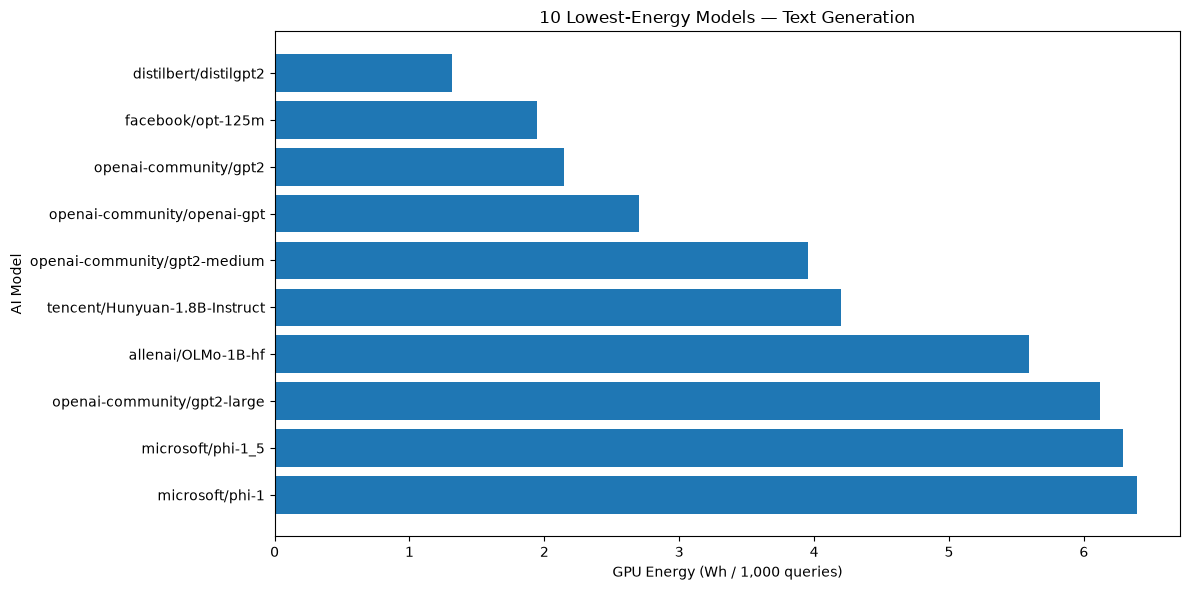

In [7]:
import matplotlib.pyplot as plt

top10 = (
    df.dropna(subset=["energy_wh_per_1k"])
      .sort_values("energy_wh_per_1k")
      .head(10)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top10["model"],
    top10["energy_wh_per_1k"]
)

plt.xlabel("GPU Energy (Wh / 1,000 queries)")
plt.ylabel("AI Model")
plt.title("10 Lowest-Energy Models — Text Generation")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()